# PeakWise Phase 2 · Bagging, boosting and stacking against strong baselines

**The question.** Do Random Forest (bagging), XGBoost (boosting) and a stacked combination predict
next-day evening consumption better than a 7-day rolling median, and is any improvement large enough
to justify the extra complexity? The answer is allowed to be "no".

**What this notebook builds on.** `phase1.py` (features, chronological splits, metrics) and the saved
model table, unchanged. Nothing from the audit or the EDA is redone. All Phase 2 logic is in `phase2.py`;
this notebook runs it (or loads its saved artifacts), tests it, and interprets it.

**Honesty notes, stated up front**
1. **The test baselines were already visible.** The Phase 1 notebook printed test-period baseline scores,
   so the test period is not blind for baselines. What is protected is the *ensemble* process: tuning
   code (`phase2.load_table(include_test=False)`) never loads a test row; model families are compared
   on validation; the test period is read **once**, by models refitted on train+validation with settings
   frozen beforehand. After the test predictions were produced, only warnings, tests and reporting code
   changed, never a model setting.
2. **One tuning rerun, before any test row was read.** The first search capped XGBoost at 600 rounds and
   several configurations chose the cap, so the cap was raised to 1,500 and the search rerun. This was
   based on cross-validation results only. Both logs are kept in `outputs/phase2/`.
3. **`macro_MAE` was misnamed in Phase 1.** It was the median of per-household MAEs. Both the mean and
   the median are now reported under their real names (`hh_MAE_mean`, `hh_MAE_median`).

In [1]:
import sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd, joblib, xgboost as xgb
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import display, Markdown

PROJECT = Path.cwd().resolve()
if not (PROJECT / "phase2.py").exists():
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT))
import phase1, phase2

OUT = phase2.OUT; OUT.mkdir(parents=True, exist_ok=True)
C = {"base": "#8a97a3", "rf": "#1f5f7a", "xgb": "#e8912d", "xgb_alt": "#f2c27b", "stack": "#c0392b", "ink": "#1f3a4d"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
                     "figure.constrained_layout.use": True})
save = lambda fig, n: fig.savefig(OUT / f"{n}.png", dpi=130, bbox_inches="tight")
pd.set_option("display.width", 200)

# Artifacts are produced by `python phase2.py all`. If they are missing, produce them now (about 12 minutes).
if not (OUT / "predictions_test.csv.gz").exists():
    phase2.run_tuning(); phase2.run_final()
print("artifacts:", sorted(p.name for p in OUT.iterdir() if p.is_file()))

artifacts: ['TUNING_AND_AI_LOG.md', 'bands_test.csv', 'bands_validation.csv', 'best_specs.json', 'deltas_validation_tr2_agree.csv', 'deltas_vs_baseline.csv', 'final_log.txt', 'household_summary.csv', 'metrics_test.csv', 'metrics_validation.csv', 'model_costs.csv', 'model_costs_with_latency.csv', 'oof_predictions_cv.csv.gz', 'p2_01_tuning.png', 'p2_02_oof_folds.png', 'p2_03_delta_vs_baseline.png', 'p2_04_bands.png', 'p2_05_household_gain.png', 'predictions_test.csv.gz', 'predictions_val.csv.gz', 'tuning_log.txt', 'tuning_log_run1_cap600.txt', 'tuning_results.csv']


## 1. Experimental design

| Element | Choice | Why |
|---|---|---|
| Data | `outputs/phase1/model_table.csv.gz`, 455,983 rows, 14 features | unchanged from Phase 1 |
| Tuning | the 3 expanding-window folds **inside the training period** | the validation and test periods stay out of tuning |
| Family comparison | validation period (models fitted on train only) | the only period used to compare models |
| Final test | models **refitted on train+validation** with frozen settings, evaluated once | standard practice; uses the most recent history a deployed model would have |
| Primary metric | MAE (kWh), RMSE (kWh) always reported beside it | MAE was the tuning criterion; RMSE exposes tail behaviour |
| Uncertainty | paired **household-level bootstrap** (400 resamples) of the difference from the baseline | rows of one household are strongly dependent, so resampling rows would give intervals that are too narrow |

**Comparison population.** Every model, baselines included, predicts **every row**. The historical baselines
answer through an explicit fallback chain (`phase2.baseline_frame`): persistence uses `lag1` and falls back
to `last_value`, the weekly rule falls back to `last_value`, and the 7-day median falls back to
`last_value` when no evening was observed in the week. No row is dropped for any model. The reference
for every comparison is the **7-day rolling median with that fallback**, the strongest baseline in
Phase 1 (best on both validation and test).

**Households absent from training** are reported separately (Section 8). The headline numbers use rows
of households that have data in the model's fitting window, so they measure *forecasting the future of
known households*, which is the project's stated goal, not generalisation to new households.

In [2]:
pv = pd.read_csv(OUT / "predictions_val.csv.gz", parse_dates=["date"])
pt = pd.read_csv(OUT / "predictions_test.csv.gz", parse_dates=["date"])
table = pd.read_csv(PROJECT / "outputs/phase1/model_table.csv.gz", usecols=["split", "y", "household_ID"])
train_y = table.loc[table.split == "train", "y"].to_numpy()

pop = pd.DataFrame({
    "rows": [len(pv), len(pt)],
    "rows from households with fitting data": [int(pv.seen_in_fit.sum()), int(pt.seen_in_fit.sum())],
    "rows from households WITHOUT fitting data": [int((~pv.seen_in_fit).sum()), int((~pt.seen_in_fit).sum())],
    "households without fitting data": [int(pv.loc[~pv.seen_in_fit, "household_ID"].nunique()), int(pt.loc[~pt.seen_in_fit, "household_ID"].nunique())],
    "date range": [f"{pv.date.min().date()} to {pv.date.max().date()}", f"{pt.date.min().date()} to {pt.date.max().date()}"],
}, index=["validation (models fitted on train)", "test (models fitted on train+validation)"])
display(pop)
missing = {c: int(pd.concat([pv, pt])[c].isna().sum()) for c in phase2.ALL_COLUMNS}
print("prediction cells missing for any model or baseline:", sum(missing.values()), "(every model answers on every row)")

,rows,rows from households with fitting data,rows from households WITHOUT fitting data,households without fitting data,date range
validation (models fitted on train),82500,82375,125,26,2024-10-01 to 2024-11-10
test (models fitted on train+validation),58404,58404,0,0,2024-11-11 to 2024-12-22


prediction cells missing for any model or baseline: 0 (every model answers on every row)


## 2. The models, and what tuning is allowed to change

* **Random Forest (bagging).** Many deep trees, each grown on a bootstrap half-sample, then averaged. Averaging
  cuts *variance*: for *B* trees with pairwise correlation ρ, variance is ρσ² + (1−ρ)σ²/*B* (lecture slide), so
  more trees only shrink the second term and the floor ρσ² is lowered only by making trees *less alike*.
  That is why the knobs worth tuning are `max_features` (a smaller subset per split decorrelates trees) and
  `min_samples_leaf` (leaf size sets how noisy each tree is). The tree count is *not* tuned: it only reduces
  variance, so it is fixed at 100 for tuning and 300 for the final model.
* **XGBoost (boosting).** Shallow trees added in sequence, each correcting the current residual, with a learning rate
  of 0.05. Boosting mainly cuts *bias*, but unchecked it overfits, so the controls that matter are tree depth
  (interaction order), `min_child_weight` and `reg_lambda` (regularisation), and the **number of rounds**. Rounds
  are tuned almost for free by reading the cross-validated error at 30 checkpoints from a single fit.
* **The choice that matters most here is the loss.** The target is strongly right-skewed and the score is MAE. The
  MAE-optimal forecast is the conditional **median**, while squared error targets the conditional **mean**, which the
  tail drags upward. So XGBoost was tried with an absolute-error objective, with squared error, and with squared
  error on `log1p(y)` (which approximates a median-type fit). Random Forest was tried on the raw and the log target.
* **Stacking** combines the tuned models (Section 3).

The search is deliberately small: 14 XGBoost and 8 Random Forest configurations, in two stages, each evaluated on
the three chronological folds (186k to 274k training rows, 37k to 51k rows validated per fold).

reference on the same folds: 7-day median baseline  cv MAE 0.4183  cv RMSE 1.2522



,name,kind,objective,target,max_depth,min_child_weight,reg_lambda,min_samples_leaf,max_features,rounds,cv_MAE,cv_RMSE,seconds
0,rf_raw_msl50_mf0.4,rf,squared error,raw,NaN,NaN,NaN,50.0,0.4,100,0.4072,1.1474,10.1656
1,rf_raw_msl50_mf1.0,rf,squared error,raw,NaN,NaN,NaN,50.0,1.0,100,0.4075,1.1689,28.0133
2,rf_raw_msl10_mf0.4,rf,squared error,raw,NaN,NaN,NaN,10.0,0.4,100,0.4075,1.1444,13.8495
3,rf_log_msl10_mf0.4,rf,squared error,log,NaN,NaN,NaN,10.0,0.4,100,0.4076,1.1864,13.6089
4,rf_log_msl50_mf1.0,rf,squared error,log,NaN,NaN,NaN,50.0,1.0,100,0.4102,1.1991,24.3475
5,rf_log_msl10_mf1.0,rf,squared error,log,NaN,NaN,NaN,10.0,1.0,100,0.4102,1.1966,38.9821
6,rf_raw_msl10_mf1.0,rf,squared error,raw,NaN,NaN,NaN,10.0,1.0,100,0.4109,1.1597,38.1889
7,rf_log_msl50_mf0.4,rf,squared error,log,NaN,NaN,NaN,50.0,0.4,100,0.4115,1.2183,8.7477
8,xgb_abs_d6_mcw50_l10,xgb,reg:absoluteerror,raw,6.0,50.0,10.0,NaN,NaN,1500,0.4184,1.2717,101.2569
9,xgb_abs_d6,xgb,reg:absoluteerror,raw,6.0,50.0,1.0,NaN,NaN,1500,0.4194,1.2794,99.9906


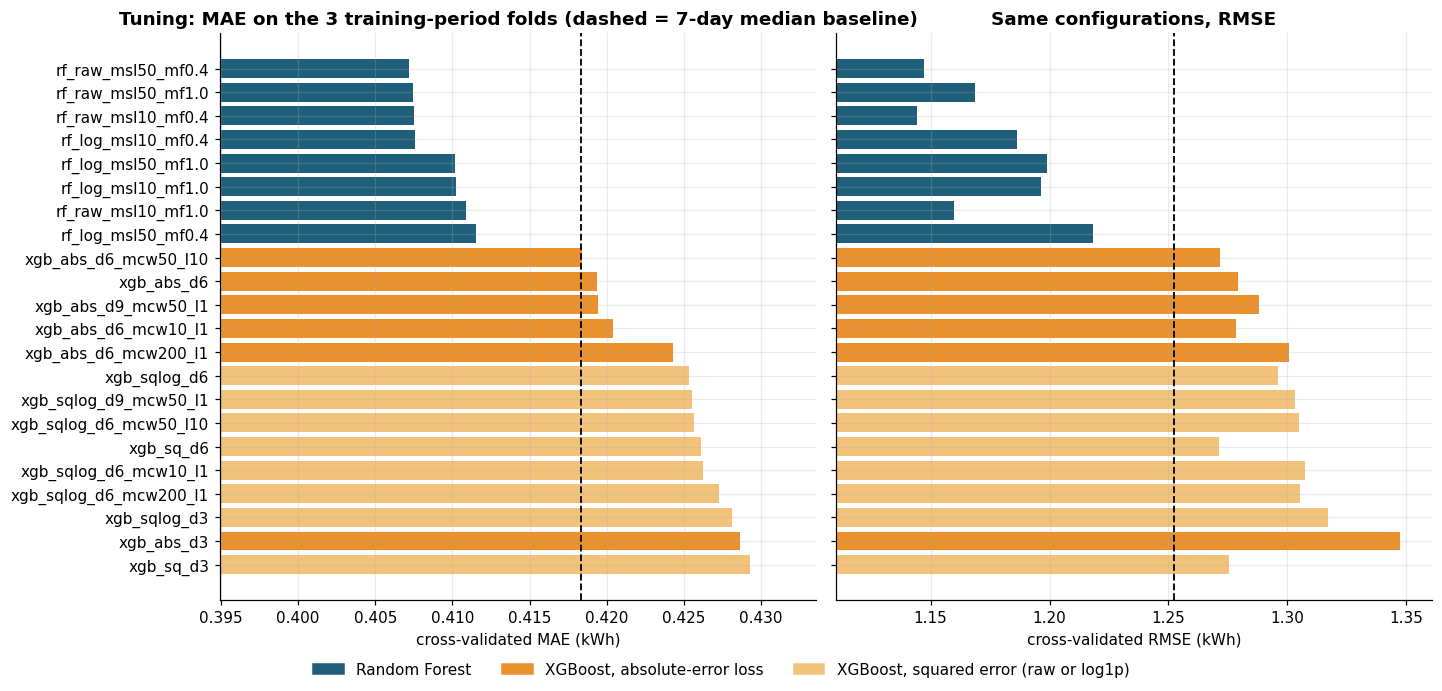

In [3]:
tune = pd.read_csv(OUT / "tuning_results.csv")
best = json.loads((OUT / "best_specs.json").read_text())
ref = best["reference_baseline_cv"]
cols = ["name", "kind", "objective", "target", "max_depth", "min_child_weight", "reg_lambda", "min_samples_leaf",
        "max_features", "rounds", "cv_MAE", "cv_RMSE", "seconds"]
t = tune[[c for c in cols if c in tune]].sort_values("cv_MAE").reset_index(drop=True)
print(f"reference on the same folds: 7-day median baseline  cv MAE {ref['cv_MAE']:.4f}  cv RMSE {ref['cv_RMSE']:.4f}\n")
display(t.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 6.2), sharey=True)
tt = t.iloc[::-1]
col = [C["rf"] if k == "rf" else (C["xgb"] if "abs" in n else C["xgb_alt"]) for k, n in zip(tt.kind, tt.name)]
for a, m, lab in zip(ax, ["cv_MAE", "cv_RMSE"], ["cross-validated MAE (kWh)", "cross-validated RMSE (kWh)"]):
    a.barh(tt.name, tt[m], color=col); a.axvline(ref[m], color="k", ls="--", lw=1.2)
    a.set_xlabel(lab); a.set_xlim(tt[m].min() * 0.97, tt[m].max() * 1.01)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=C["rf"], label="Random Forest"), Patch(color=C["xgb"], label="XGBoost, absolute-error loss"),
                    Patch(color=C["xgb_alt"], label="XGBoost, squared error (raw or log1p)")], loc="outside lower center", ncol=3)
ax[0].set_title("Tuning: MAE on the 3 training-period folds (dashed = 7-day median baseline)")
ax[1].set_title("Same configurations, RMSE")
save(fig, "p2_01_tuning"); plt.show()

**What tuning changed, and what mattered.**

* **The baseline sets a hard bar.** On the same folds the 7-day median scores MAE 0.4183 and RMSE 1.2522.
  The best Random Forest reaches MAE 0.4072 and RMSE 1.1474 (2.7% and 8.4% better). The best XGBoost reaches
  MAE 0.4184 and RMSE 1.2717, i.e. **no better than the baseline on MAE and slightly worse on RMSE**.
* **Loss and target matter more than anything else for XGBoost.** At depth 6, the absolute-error loss
  (MAE 0.4194) beats squared error on the raw target (0.4261) and on `log1p` (0.4253). It also costs about
  6× more to tune and needs about 10× more boosting rounds (up to the 1,500 limit, where returns are
  already tiny: 0.4194 at λ=1 vs 0.4184 at λ=10).
* **Depth:** depth 3 is clearly worse for the absolute-error loss (0.4287 vs 0.4194); depth 9 does not beat
  depth 6 (0.4195 at 650 rounds). Larger `min_child_weight` (200) hurt (0.4243); a stronger L2 penalty
  (λ=10) helped slightly. These are small, plausible bias–variance moves, not breakthroughs.
* **Random Forest:** a smaller `max_features` (0.4 of the features) lowered MAE in 3 of the 4 pairings (the exception is the
  log-target at leaf size 50) and RMSE in 3 of 4 too, as the correlation argument predicts (1.1474 vs 1.1689 at the same leaf size). Leaf size
  10 vs 50 hardly changed MAE (0.4075 vs 0.4072), so the larger, cheaper leaf was chosen. The raw
  target beat `log1p` for RMSE (1.147 vs 1.218) because back-transforming a log-scale fit under-predicts
  the large days that dominate squared error.
* **Selection rule (fixed beforehand):** the lowest mean cross-validated MAE within each family. The second XGBoost
  (`xgb_alt`) is the best configuration of the *other* loss family, kept for the stack because it makes
  different mistakes.

## 3. Leakage-safe stacking

**Architecture.** Level-0 inputs: the tuned Random Forest, the tuned absolute-error XGBoost, the best squared-error
XGBoost, and the 7-day median baseline (so the meta-learner may fall back on it). Level-1: a **non-negative linear
combination without intercept**, fitted by least squares. It is the simplest learner that can still weight the
models, its weights can be read directly, it cannot extrapolate wildly, and with about 129,000 out-of-fold rows
for four inputs there is no real risk of overfitting it. More flexible meta-learners were not tried: with
four correlated inputs and a skewed target they would mainly add variance.

**How the out-of-fold predictions are made.** For each of the three chronological folds a base model is fitted
**only on rows dated before that fold's validation window** and predicts only that window. The validation period is
a fourth window (base models fitted on train only). Nothing is ever predicted by a model that was fitted on it.

* To **evaluate on validation**, the meta-learner is fitted on folds 1 to 3 only (all dated ≤ 2024-09-30).
* To **evaluate on test**, it is fitted on folds 1 to 3 plus validation (all dated ≤ 2024-11-10), and the base
  models are refitted on train+validation to predict the test period.

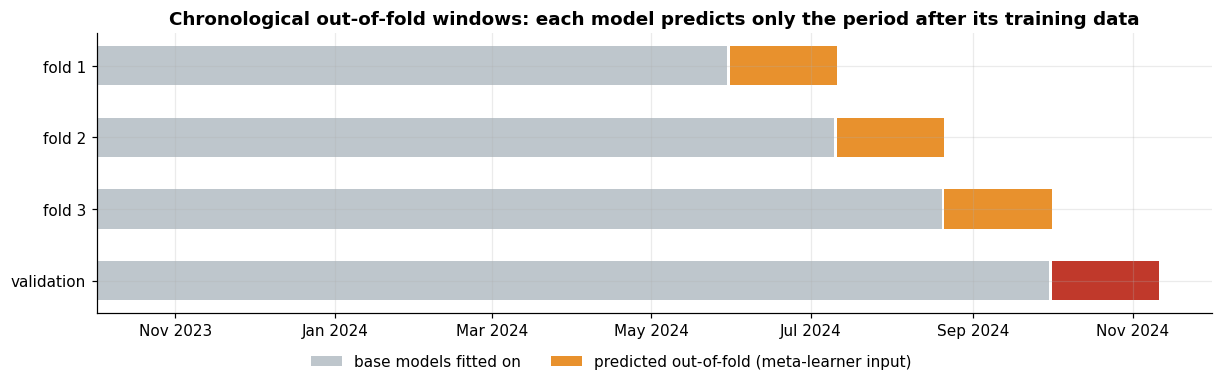

meta weights used for VALIDATION: {'rf': 0.909, 'xgb': 0.0, 'xgb_alt': 0.109, 'baseline_roll7': 0.0}
meta weights used for TEST:       {'rf': 0.948, 'xgb': 0.063, 'xgb_alt': 0.0, 'baseline_roll7': 0.0}


In [4]:
m_dates = phase2.load_table(include_test=False)            # the same call tuning used: no test rows
folds = phase1.cv_folds(m_dates)
fig, ax = plt.subplots(figsize=(11, 3.4))
rows = []
for k, (a, b) in enumerate(folds, 1):
    rows.append((f"fold {k}", m_dates.date.iloc[a].min(), m_dates.date.iloc[a].max(), m_dates.date.iloc[b].min(), m_dates.date.iloc[b].max()))
rows.append(("validation", m_dates.date.min(), pd.Timestamp(phase2.TRAIN_END), pd.Timestamp(phase1.SPLIT_DATES["val"][0]), phase2.VAL_END))
for i, (lab, t0, t1, v0, v1) in enumerate(rows):
    ax.barh(i, (t1 - t0).days, left=mdates.date2num(t0), color=C["base"], alpha=.55, height=.55, label="base models fitted on" if i == 0 else None)
    ax.barh(i, (v1 - v0).days + 1, left=mdates.date2num(v0), color=C["stack"] if lab == "validation" else C["xgb"], height=.55,
            label="predicted out-of-fold (meta-learner input)" if i == 0 else None)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=2)
ax.set_title("Chronological out-of-fold windows: each model predicts only the period after its training data")
save(fig, "p2_02_oof_folds"); plt.show()

man = json.loads((OUT / "models/manifest.json").read_text())
print("meta weights used for VALIDATION:", {k: round(v, 3) for k, v in man["stack_weights_for_validation"].items()})
print("meta weights used for TEST:      ", {k: round(v, 3) for k, v in man["stack_weights_for_test"].items()})

In [5]:
# the correctness suite: chronology of every OOF fit, meta-learner training dates, future-corruption of the stack,
# independent least-squares check of the weights, metric definitions, evaluation population
r = subprocess.run([sys.executable, "check_phase2.py"], cwd=PROJECT, capture_output=True, text=True)
lines = [l for l in (r.stdout + r.stderr).splitlines() if " ... " in l or l.startswith(("Ran", "OK", "FAILED"))]
print("\n".join(lines[-22:]))
assert r.returncode == 0, "Phase 2 correctness checks FAILED"

test_back_transform_is_non_negative_and_inverts_log (__main__.EvaluationCorrectness) ... ok
test_every_baseline_answers_on_every_row (__main__.EvaluationCorrectness) ... ok
test_household_mae_mean_and_median_are_what_they_say (__main__.EvaluationCorrectness) ... ok
test_paired_bootstrap_point_estimate_equals_direct_difference (__main__.EvaluationCorrectness) ... ok
test_unseen_households_are_flagged_correctly (__main__.EvaluationCorrectness) ... ok
test_saved_predictions_match_recomputed_metrics (__main__.SavedArtifactsAreConsistent) ... ok
test_every_oof_model_was_fitted_strictly_before_the_window_it_predicts (__main__.StackingIsChronologicalAndLeakFree) ... ok
test_folds_are_disjoint_and_inside_the_training_period (__main__.StackingIsChronologicalAndLeakFree) ... ok
The decisive test: corrupt targets the stack must not see and require identical predictions. ... ok
test_meta_learner_is_fitted_only_on_rows_before_validation (__main__.StackingIsChronologicalAndLeakFree) ... ok
test_meta

**What the checks establish.**

* Every out-of-fold model's training data ends strictly before the window it predicts, and the fold windows never overlap.
* The meta-learner's training rows end on 2024-09-30 (validation evaluation) or 2024-11-10 (test evaluation).
* **Future corruption:** multiplying the *test* targets by 1,000 changes no validation or test prediction at all;
  multiplying the *validation* targets by 1,000 changes no validation prediction; and multiplying the *training* targets
  does change them (so the check is not vacuous). A leak of future target values anywhere in the stack would break one
  of these.
* The meta weights match an independent least-squares solution, and are non-negative.

**Observed weights.** For the validation evaluation the meta-learner puts 0.91 on Random Forest, 0.11 on the squared-error XGBoost and **zero
on the absolute-error XGBoost and on the baseline**; for the test evaluation (refitted with the validation period included) 0.95 on Random Forest,
0.06 on the absolute-error XGBoost and zero elsewhere. Either way the stack is, to a first approximation, Random Forest with a small adjustment, which
already suggests it cannot do much better than Random Forest. Section 4 confirms that. A reason is worth noting: least squares
minimises *squared* error, so it favours the model that is best in squared error (Random Forest), while the score we care about is MAE.

## 4. Results: validation and test

All rows of households with data in the fitting window (validation: 82,375 rows; test: 58,404 rows). `MAE_vs_ref_%`
is the change relative to the 7-day median baseline (negative = better). The last row, `equal-weight average`, is a
diagnostic that was **not** a candidate and is not used to select anything.

In [6]:
sv, st_ = pv.seen_in_fit.to_numpy(), pt.seen_in_fit.to_numpy()
tv, tt_ = phase2.metrics_table(pv, sv), phase2.metrics_table(pt, st_)
show = ["MAE", "RMSE", "MedAE", "hh_MAE_mean", "hh_MAE_median", "MAE_vs_ref_%", "RMSE_vs_ref_%"]
lab = lambda t: t.rename(index=phase2.LABELS)
print("VALIDATION (models fitted on train only)"); display(lab(tv)[show].round(4))
print("TEST (models refitted on train+validation; read once)"); display(lab(tt_)[show].round(4))
tv.to_csv(OUT / "metrics_validation.csv"); tt_.to_csv(OUT / "metrics_test.csv")

VALIDATION (models fitted on train only)


,MAE,RMSE,MedAE,hh_MAE_mean,hh_MAE_median,MAE_vs_ref_%,RMSE_vs_ref_%
model,,,,,,,
baseline: global median,0.9029,2.5783,0.4390,1.0003,0.4443,185.7779,155.1218
baseline: persistence,0.3586,1.0601,0.1329,0.3889,0.1943,13.4959,4.8929
baseline: same weekday last week,0.4074,1.1583,0.1520,0.4307,0.2152,28.9325,14.6091
baseline: 28-day median,0.3253,1.0533,0.1205,0.3533,0.1713,2.9596,4.2186
baseline: all-history median,0.3753,1.1255,0.1509,0.4172,0.2005,18.7974,11.3676
baseline: 7-day median (reference),0.3159,1.0106,0.1165,0.3456,0.1681,0.0000,0.0000
Random Forest (bagging),0.3105,0.9321,0.1228,0.3400,0.1662,-1.7177,-7.7706
"XGBoost, absolute-error loss (boosting)",0.3079,1.0342,0.1138,0.3481,0.1603,-2.5515,2.3366
"XGBoost, squared-error on log1p (boosting)",0.3111,1.0526,0.1190,0.3513,0.1640,-1.5336,4.1489


TEST (models refitted on train+validation; read once)


,MAE,RMSE,MedAE,hh_MAE_mean,hh_MAE_median,MAE_vs_ref_%,RMSE_vs_ref_%
model,,,,,,,
baseline: global median,0.8687,3.6378,0.4021,0.8510,0.4002,197.8457,113.3381
baseline: persistence,0.3286,1.8030,0.1220,0.3317,0.1790,12.6710,5.7344
baseline: same weekday last week,0.3694,1.7480,0.1460,0.3715,0.2107,26.6449,2.5105
baseline: 28-day median,0.3039,1.8975,0.1135,0.3004,0.1616,4.1937,11.2767
baseline: all-history median,0.3734,2.2116,0.1461,0.3671,0.1881,28.0110,29.6974
baseline: 7-day median (reference),0.2917,1.7052,0.1090,0.2928,0.1583,0.0000,0.0000
Random Forest (bagging),0.2862,1.6068,0.1139,0.2876,0.1574,-1.8833,-5.7666
"XGBoost, absolute-error loss (boosting)",0.2997,1.8181,0.1063,0.3054,0.1519,2.7447,6.6200
"XGBoost, squared-error on log1p (boosting)",0.3092,1.9518,0.1114,0.3087,0.1563,5.9909,14.4610


d_MAE  d_MAE_lo  d_MAE_hi  d_RMSE  d_RMSE_lo  d_RMSE_hi
period     model                                                            
validation rf      -0.0054   -0.0080   -0.0024 -0.0785    -0.1257    -0.0261
           xgb     -0.0081   -0.0149    0.0023  0.0236    -0.0587     0.1658
           xgb_alt -0.0048   -0.0109    0.0053  0.0419    -0.0460     0.1780
           stack   -0.0029   -0.0060    0.0002 -0.0746    -0.1187    -0.0233
test       rf      -0.0055   -0.0100    0.0004 -0.0983    -0.1596    -0.0393
           xgb      0.0080   -0.0096    0.0393  0.1129     0.0033     0.3418
           xgb_alt  0.0175   -0.0034    0.0528  0.2466     0.0379     0.4179
           stack   -0.0045   -0.0089    0.0014 -0.0988    -0.1605    -0.0368

difference = model minus 7-day median baseline; negative = model better; 95% interval from a household-level bootstrap


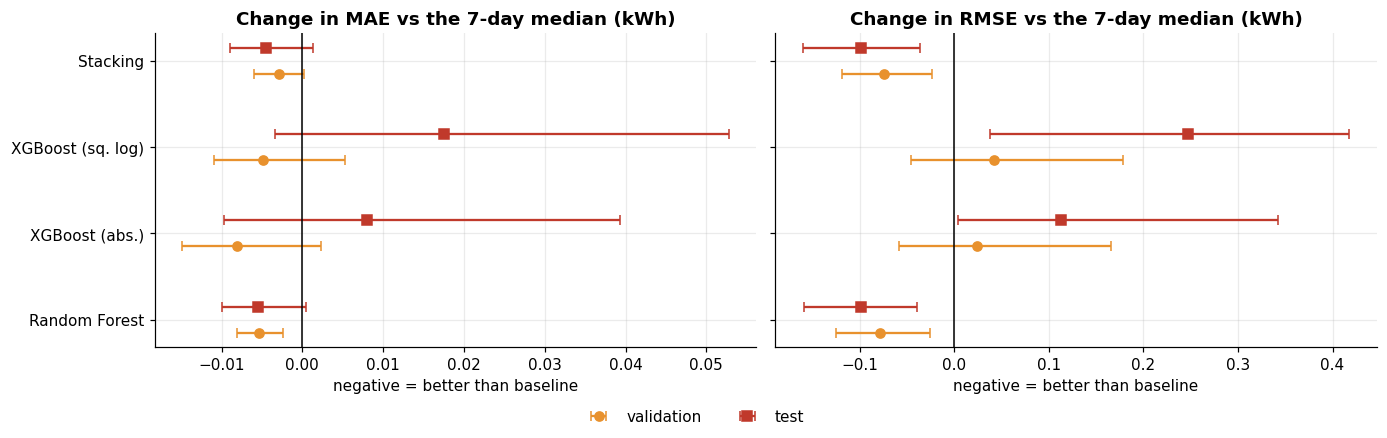

In [7]:
dv, dt_ = phase2.delta_table(pv, sv), phase2.delta_table(pt, st_)
dd = pd.concat({"validation": dv, "test": dt_}, names=["period"]).round(4)
dd.to_csv(OUT / "deltas_vs_baseline.csv")
display(dd[["d_MAE", "d_MAE_lo", "d_MAE_hi", "d_RMSE", "d_RMSE_lo", "d_RMSE_hi"]])
print("difference = model minus 7-day median baseline; negative = model better; 95% interval from a household-level bootstrap")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
names = {"rf": "Random Forest", "xgb": "XGBoost (abs.)", "xgb_alt": "XGBoost (sq. log)", "stack": "Stacking"}
for a, (metric, title) in zip(ax, [("MAE", "Change in MAE vs the 7-day median (kWh)"), ("RMSE", "Change in RMSE vs the 7-day median (kWh)")]):
    for j, (per, d, mk) in enumerate([("validation", dv, "o"), ("test", dt_, "s")]):
        y = np.arange(len(d)) + (j - .5) * .3
        a.errorbar(d[f"d_{metric}"], y, xerr=[d[f"d_{metric}"] - d[f"d_{metric}_lo"], d[f"d_{metric}_hi"] - d[f"d_{metric}"]],
                   fmt=mk, color=[C["xgb"], C["stack"]][j], capsize=3, label=per)
    a.axvline(0, color="k", lw=1); a.set_yticks(range(len(dv))); a.set_yticklabels([names[k] for k in dv.index]); a.invert_yaxis()
    a.set_title(title); a.set_xlabel("negative = better than baseline")
fig.legend(*ax[0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
save(fig, "p2_03_delta_vs_baseline"); plt.show()

**What we can conclude (and how firmly).**

1. **Which model is best, by metric.**
   * *MAE:* Random Forest on test (0.2862 vs the baseline 0.2917) and XGBoost on validation (0.3079 vs 0.3159).
   * *RMSE:* Random Forest on validation (0.9321 vs 1.0106) and on test (1.6068 vs 1.7052), with the stack level with it
     on test (1.6064).
   * *Median error and per-household median:* XGBoost with the absolute-error loss, which targets the median.
   So **there is no single winner.** Random Forest is the most consistent: ahead of the baseline on both metrics in both periods.
2. **Do the ensembles meaningfully beat the rolling median? Barely.** The MAE gains are about 2% (Random Forest 1.7% on
   validation, 1.9% on test) and their intervals touch or cross zero on test (−0.0055, 95% interval −0.0100 to +0.0004).
   The RMSE gain of Random Forest is larger (about 8% on validation, 6% on test) and its interval excludes zero in both
   periods. In plain terms: on a typical evening the forecast improves by about 0.005 kWh, and the improvement is clearest
   on the large days that dominate squared error.
3. **XGBoost does not reliably beat the baseline.** Its MAE gain on validation (−0.0081) has an interval spanning zero, on
   test it is worse (+0.0080, interval also spanning zero) and its RMSE is worse in both periods (+0.0236 on validation, not clearly; +0.1129 on
   test, interval excluding zero). The gradient-boosted models are better at the median and worse in the tail.
4. **Does stacking improve on the best individual model? No.** The stack's MAE (0.3130 validation, 0.2872 test) and RMSE
   (0.9360, 1.6064) are essentially Random Forest's (0.3105 / 0.2862; 0.9321 / 1.6068), as the weights predicted. The extra machinery
   bought nothing here. One nuance: the equal-weight average, which was *not* a candidate, has the lowest MAE of any row on validation (0.3049) but not on test
   (0.2889, behind Random Forest). So averaging dissimilar models may help MAE a little, and the fitted meta-learner did not capture it, probably
   because it minimises squared error while the score is MAE. A meta-learner trained on absolute error is the obvious untried alternative, and
   this is one reason the stacking result should be read as "no gain from *this* stack", not "stacking cannot help".

## 5. Typical versus unusually high consumption

Bands use the **training** percentiles of the target (P25 0.33, P75 1.29, P95 4.4, P99 12.2 kWh). `bias` is the mean signed error
(forecast minus actual): negative means under-forecasting. The extreme band is small and concentrated in a handful of households,
so it is shown but should not be over-read.

VALIDATION


,n,households,MAE base_roll7_median,MAE rf,MAE xgb,MAE stack,bias base_roll7_median,bias rf,bias xgb,bias stack
band,,,,,,,,,,
exactly 0,6082,371,0.051,0.079,0.043,0.078,0.051,0.079,0.043,0.078
low (<P25),13362,1149,0.125,0.152,0.120,0.155,0.095,0.140,0.095,0.143
typical (P25-P75),43491,2115,0.187,0.183,0.173,0.186,0.034,0.065,0.032,0.077
high (P75-P95),16519,1190,0.585,0.556,0.549,0.559,-0.108,0.002,-0.112,0.031
very high (P95-P99),2433,281,1.685,1.537,1.606,1.527,-0.961,-0.813,-1.005,-0.735
extreme (>P99),488,41,4.412,4.445,6.141,4.490,-3.277,-3.246,-4.625,-3.067


TEST


,n,households,MAE base_roll7_median,MAE rf,MAE xgb,MAE stack,bias base_roll7_median,bias rf,bias xgb,bias stack
band,,,,,,,,,,
exactly 0,4604,333,0.061,0.085,0.043,0.083,0.061,0.085,0.043,0.083
low (<P25),10566,998,0.130,0.147,0.117,0.148,0.099,0.135,0.091,0.135
typical (P25-P75),32701,1708,0.206,0.189,0.176,0.190,0.045,0.061,0.024,0.067
high (P75-P95),8988,798,0.547,0.500,0.517,0.498,-0.200,-0.164,-0.258,-0.148
very high (P95-P99),1136,124,1.605,1.543,1.643,1.539,-0.861,-0.798,-0.989,-0.739
extreme (>P99),409,21,4.614,5.736,9.324,5.833,-1.911,-4.470,-7.354,-4.324


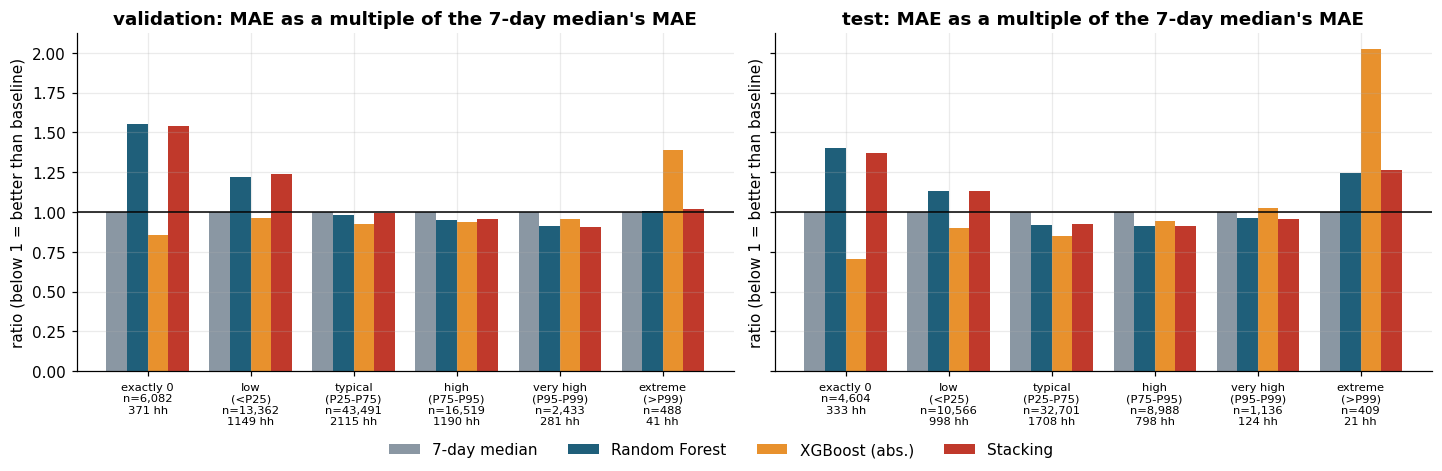

In [8]:
bv, bt = phase2.band_table(pv[sv], train_y), phase2.band_table(pt[st_], train_y)
bv.to_csv(OUT / "bands_validation.csv"); bt.to_csv(OUT / "bands_test.csv")
for nm, b in (("VALIDATION", bv), ("TEST", bt)):
    print(nm); display(b[["n", "households"] + [c for c in b if c.startswith("MAE")] + [c for c in b if c.startswith("bias")]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, (nm, b) in zip(ax, (("validation", bv), ("test", bt))):
    x = np.arange(len(b)); w = .2
    for j, (k, col, lb) in enumerate([("base_roll7_median", C["base"], "7-day median"), ("rf", C["rf"], "Random Forest"),
                                      ("xgb", C["xgb"], "XGBoost (abs.)"), ("stack", C["stack"], "Stacking")]):
        a.bar(x + (j - 1.5) * w, b[f"MAE {k}"] / b["MAE base_roll7_median"], width=w, color=col, label=lb)
    a.axhline(1, color="k", lw=1); a.set_xticks(x)
    a.set_xticklabels([f"{i.replace(' (', chr(10) + '(')}\nn={int(r.n):,}\n{int(r.households)} hh" for i, r in b.iterrows()], fontsize=7.5)
    a.set_title(f"{nm}: MAE as a multiple of the 7-day median's MAE"); a.set_ylabel("ratio (below 1 = better than baseline)")
fig.legend(*ax[0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
save(fig, "p2_04_bands"); plt.show()

**What we can see.**

* **Typical evenings (the middle 50%): all three ensembles beat the baseline in both periods** (test MAE 0.189 Random Forest, 0.176
  XGBoost, 0.190 stack against 0.206). This is where boosting is strongest, and it holds on 32,701 test rows from 1,708 households.
* **Quiet evenings are where the models lose.** On exactly-zero days the baseline is off by 0.061 kWh but Random Forest by 0.085 and the stack
  by 0.083 (they cannot commit to zero and spread a small positive forecast). XGBoost with the absolute-error loss is the best of all here (0.043),
  as the median-targeting argument predicts. On the lowest quarter (below P25) Random Forest and the stack are again worse than the baseline.
* **High evenings (P75 to P99): modest gains.** Random Forest and the stack improve on the baseline by roughly 4 to 9% in MAE in both periods; XGBoost is mixed (better in P75-P95, slightly worse on test in P95-P99).
* **Extreme evenings (above P99): the ensembles are no better and often worse.** All models under-forecast them heavily (mean error −1.9 kWh for the baseline,
  −4.5 for Random Forest and −7.4 for XGBoost on test). Test MAE here is 4.6 (baseline), 5.7 (Random Forest), 9.3 (XGBoost). But this band is
  **409 test rows from only 21 households** (488 rows from 41 on validation), and the two periods disagree on how much worse Random Forest is
  (4.445 vs 4.412 on validation). Treat it as *a warning that these days are not being learned*, not as an estimate of how much worse.
  A plausible but **unverified** reading: extreme days are rare and mostly not predictable from a household's recent past, so a model trained to
  minimise average error learns to predict the typical level for rows that look like them, and lands far below the extreme value.

## 6. Per-household view

Per-household MAE differences (model minus baseline, one number per household) show whether the average gain is broad or
carried by a few households.

households  share of households improved %  median change in household MAE  mean change  10th pct change  90th pct change
period     model                                                                                                                           
validation rf           2651                         56.8842                         -0.0033      -0.0056          -0.0485           0.0337
           xgb          2651                         67.6726                         -0.0064       0.0024          -0.0576           0.0120
           stack        2651                         53.1498                         -0.0016      -0.0026          -0.0478           0.0363
test       rf           2120                         55.1415                         -0.0025      -0.0052          -0.0469           0.0306
           xgb          2120                         62.0755                         -0.0046       0.0126          -0.0553           0.0174
           stack        2120                         54.3396                         -0.0020      -0.0041          -0.0468           0.0310

TEST, Random Forest: total absolute-error change -320.8 kWh; the 10 most-improved households contribute -132.9, the 10 most-worsened 231.8


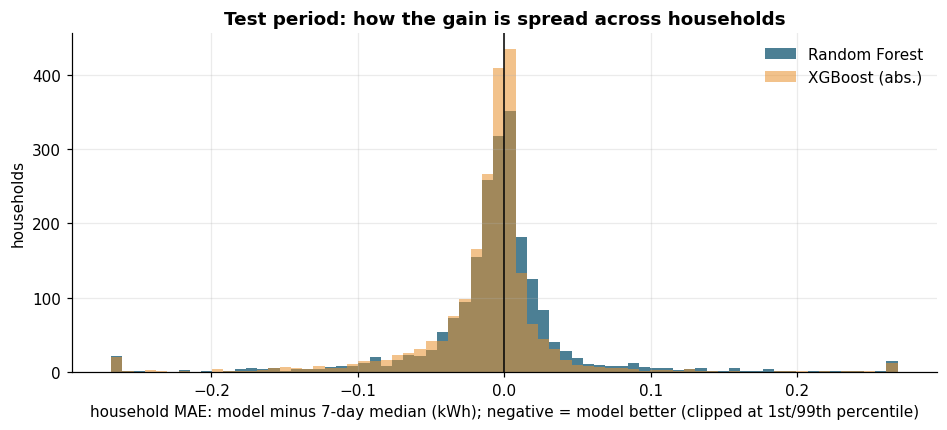

In [9]:
hv, ht = phase2.household_table(pv[sv]), phase2.household_table(pt[st_])
rows = []
for nm, h in (("validation", hv), ("test", ht)):
    for k in ("rf", "xgb", "stack"):
        d = h[f"d_{k}"]
        rows.append({"period": nm, "model": k, "households": len(h), "share of households improved %": 100 * (d < 0).mean(),
                     "median change in household MAE": d.median(), "mean change": d.mean(),
                     "10th pct change": d.quantile(.1), "90th pct change": d.quantile(.9)})
hh_res = pd.DataFrame(rows).set_index(["period", "model"]); hh_res.to_csv(OUT / "household_summary.csv")
display(hh_res.round(4))

s = pt[st_].assign(d=lambda x: (x.rf - x.y).abs() - (x.base_roll7_median - x.y).abs())
top = s.groupby("household_ID").d.sum().sort_values()
print(f"TEST, Random Forest: total absolute-error change {s.d.sum():.1f} kWh; the 10 most-improved households contribute {top.head(10).sum():.1f}, "
      f"the 10 most-worsened {top.tail(10).sum():.1f}")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
lim = ht["d_rf"].quantile([.01, .99]).abs().max()
ax.hist(ht["d_rf"].clip(-lim, lim), bins=70, color=C["rf"], alpha=.8, label="Random Forest")
ax.hist(ht["d_xgb"].clip(-lim, lim), bins=70, color=C["xgb"], alpha=.55, label="XGBoost (abs.)")
ax.axvline(0, color="k", lw=1); ax.set_xlabel("household MAE: model minus 7-day median (kWh); negative = model better (clipped at 1st/99th percentile)")
ax.set_ylabel("households"); ax.set_title("Test period: how the gain is spread across households"); ax.legend()
save(fig, "p2_05_household_gain"); plt.show()

**What we can see.** About **55% of households improve with Random Forest and 62% with XGBoost** on test (57% and 68% on validation), and the median
household's MAE changes by only about −0.003 kWh. So most households see a tiny effect. The distribution is asymmetric: improvements are spread over
many households, while the households that get *worse* are concentrated. On test the ten most-worsened households add 232 kWh of absolute error, more than the ten
most-improved save (133 kWh), and XGBoost's mean household change is positive (+0.013 kWh) even though its median is negative (−0.005 kWh). This is not a method that
transforms forecasting for the typical household, and a handful of households can offset a visible part of the gain.

## 7. Robustness: the `tr2_check == "agree"` subset

The audit marked a day `agree` when the meter's own peak-period register (TR2) reproduced the extracted evening value. **This check can only be
run on validation**: the six-hour register has no usable bracket after 31 October 2024, so **every test row is `no_bracket`**. That is a limitation:
the test-period targets are valid under the audit's rules but cannot be cross-checked against the meter.

In [10]:
both = pd.concat([pv.assign(period="validation"), pt.assign(period="test")], ignore_index=True)
print(pd.crosstab(both.period, both.tr2_check).to_string())
agree = (pv.seen_in_fit & (pv.tr2_check == "agree")).to_numpy()
rest = (pv.seen_in_fit & (pv.tr2_check != "agree")).to_numpy()
ta, tr_ = phase2.metrics_table(pv, agree), phase2.metrics_table(pv, rest)
cmp = pd.concat({"all validation rows": tv, "tr2 agree (October)": ta, "not agree (mostly 1-10 Nov)": tr_}, axis=1)
show_rows = ["base_roll7_median", "rf", "xgb", "stack"]
print(); display(cmp.loc[show_rows, [(g, c) for g in cmp.columns.levels[0] for c in ("MAE", "RMSE")]].round(4))
da = phase2.delta_table(pv, agree); da.to_csv(OUT / "deltas_validation_tr2_agree.csv")
display(da[["d_MAE", "d_MAE_lo", "d_MAE_hi", "d_RMSE", "d_RMSE_lo", "d_RMSE_hi"]].round(4))
mon = pv[sv].assign(month=lambda d: d.date.dt.strftime("%Y-%m"))
display(pd.DataFrame({k: (mon[k] - mon.y).abs().groupby(mon["month"]).mean() for k in ["base_roll7_median", "rf", "xgb", "stack"]})
        .assign(rows=mon.groupby("month").size()).round(4))

tr2_check   agree  disagree  no_bracket  plateau_inconsistent
period                                                       
test            0         0       58404                     0
validation  55601        22       26531                   346


all validation rows         tr2 agree (October)         not agree (mostly 1-10 Nov)        
                                  MAE    RMSE                 MAE    RMSE                         MAE    RMSE
model                                                                                                        
base_roll7_median              0.3159  1.0106              0.3265  0.9011                      0.2940  1.2064
rf                             0.3105  0.9321              0.3203  0.8238                      0.2903  1.1239
xgb                            0.3079  1.0342              0.3126  0.8533                      0.2981  1.3333
stack                          0.3130  0.9360              0.3229  0.8255                      0.2926  1.1313

,d_MAE,d_MAE_lo,d_MAE_hi,d_RMSE,d_RMSE_lo,d_RMSE_hi
model,,,,,,
rf,-0.0063,-0.0098,-0.0027,-0.0773,-0.1117,-0.0435
xgb,-0.0139,-0.0194,-0.0076,-0.0478,-0.0776,-0.0089
xgb_alt,-0.0113,-0.0160,-0.0073,-0.0537,-0.0772,-0.0295
stack,-0.0037,-0.0073,0.0000,-0.0756,-0.1092,-0.0411


,base_roll7_median,rf,xgb,stack,rows
month,,,,,
2024-10,0.3258,0.3195,0.3114,0.3221,61804
2024-11,0.2863,0.2834,0.2973,0.2856,20571


**What we learn, and what we should not.** On the 55,571 validation rows marked `agree`, the ensembles look **better**: XGBoost's MAE gain becomes
clear (−0.0139, interval excluding zero) and its RMSE is no longer worse than the baseline; Random Forest's gains are similar to before.
But the check is **confounded with the calendar**: validation covers 1 October to 10 November, and every `agree` row is in October, because the meter
cross-check stops on 31 October. The month table shows that XGBoost beats the baseline in October (0.3114 vs 0.3258) but loses in November (0.2973 vs 0.2863), and the November rows are
exactly the rows without a meter check. So we cannot separate "days the meter confirms" from "October rather than November", and we should *not* conclude that
XGBoost is good on verified data and bad on unverified data. What *is* robust is the Random Forest result (better RMSE on the subset and on the rest) and the lesson that
the ranking of XGBoost against the baseline is **sensitive to the period** (October versus November), which is itself a warning about how
much a 6-week evaluation window can say.

## 8. Households absent from the fitting data

Validation contains 125 rows from 26 households with no training rows; the test period has none, because every test household appears in train+validation.
These rows are excluded from the headline results above and reported separately here, with the obvious caution that 125 rows is too few to conclude anything.

In [11]:
u = pv[~pv.seen_in_fit]
display(pd.DataFrame({"rows": [len(u)], "households": [u.household_ID.nunique()],
                      **{k: [float(np.abs(u[k] - u.y).mean())] for k in ["base_roll7_median", "rf", "xgb", "stack"]}},
                     index=["MAE on unseen-household rows (validation)"]).round(3))
print("scope: the results above measure forecasting the FUTURE OF KNOWN HOUSEHOLDS. They say nothing reliable about a household that joins later.")

,rows,households,base_roll7_median,rf,xgb,stack
MAE on unseen-household rows (validation),125,26,0.348,0.361,0.36,0.359


scope: the results above measure forecasting the FUTURE OF KNOWN HOUSEHOLDS. They say nothing reliable about a household that joins later.


## 9. Cost and complexity

Training time is for the train-only fit (315,079 rows); the saved dashboard models are refitted on train+validation. Latency is measured on the saved
models; Random Forest is timed with one thread and with ten, because thread start-up dominates a single prediction.

In [12]:
costs = pd.read_csv(OUT / "model_costs.csv", index_col=0)
mods = {}; sample = pd.read_csv(PROJECT / "outputs/phase1/model_table.csv.gz", parse_dates=["date"]).query("split == 'val'").head(20000)
specs = best
rf = joblib.load(OUT / "models/rf.joblib"); mods["rf"] = rf
for n in ("xgb", "xgb_alt"):
    mm = xgb.XGBRegressor(); mm.load_model(str(OUT / f"models/{n}.ubj")); mods[n] = mm
lat = {n: phase2.measure_latency(specs[n], mods[n], sample) for n in mods}
tune_sec = {"rf": tune[tune.kind == "rf"].seconds.median(),
            "xgb": tune[tune.objective == "reg:absoluteerror"].seconds.median(),
            "xgb_alt": tune[(tune.objective == "reg:squarederror") & (tune.target == "log")].seconds.median()}
rows = []
for n in ("rf", "xgb", "xgb_alt"):
    f = OUT / "models" / (f"{n}.joblib" if n == "rf" else f"{n}.ubj")
    rows.append({"model": n, "trees": int(costs.loc[n, "n_trees"]), "train seconds": costs.loc[n, "train_seconds"],
                 "tuning seconds per config (3 folds)": tune_sec[n], "size on disk (MB)": f.stat().st_size / 1e6, **lat[n]})
cost_tbl = pd.DataFrame(rows).set_index("model"); cost_tbl.to_csv(OUT / "model_costs_with_latency.csv")
display(cost_tbl.round(3))
print("stacking = the three models above + a 4-weight linear combination; its cost is the sum of its parts (about 3x the single-model cost) plus a negligible meta step")

,trees,train seconds,tuning seconds per config (3 folds),size on disk (MB),ms_per_1000_rows_1thread,single_row_ms_1thread,ms_per_1000_rows_allthreads,single_row_ms_allthreads,ms_per_1000_rows,single_row_ms
model,,,,,,,,,,
rf,300,14.605,19.098,37.819,18.606,7.633,3.651,14.608,NaN,NaN
xgb,1500,42.784,100.624,5.423,NaN,NaN,NaN,NaN,2.127,0.188
xgb_alt,150,0.644,15.627,0.589,NaN,NaN,NaN,NaN,0.256,0.214


stacking = the three models above + a 4-weight linear combination; its cost is the sum of its parts (about 3x the single-model cost) plus a negligible meta step


**Reading the cost table.** The squared-error XGBoost trains in under a second and is 0.6 MB; the absolute-error XGBoost takes about 43 s
to train, needs 1,500 trees (5 MB), and costs roughly 100 s per tuning configuration. Random Forest trains in about 15 s but is the largest file
(about 38 MB compressed for the refitted model). Predicting 1,000 rows takes about 2 ms (XGBoost), 4 to 19 ms (Random Forest, ten threads or one),
and one row takes 0.2 ms (XGBoost) or 8 to 14 ms (Random Forest, dominated by thread start-up), so latency is a non-issue for a dashboard. The stack must
run every base model, so its cost is the sum of the three and its serving complexity is higher, for no accuracy gain.

## 10. Conclusions

**Which model is best?** There is no single winner and the differences are small. Random Forest is the **most consistent**: it improves on the 7-day median
in both periods on both MAE (about 2%) and RMSE (6 to 8%), and its RMSE gain is the only gain whose interval clearly excludes zero in both periods. XGBoost wins
on median-type measures and on typical days but loses in the tail, and is not reliably better than the baseline overall. Stacking equals Random Forest.

**Do ensembles justify their complexity?** Only modestly. The honest summary is that a 7-day rolling median is a very strong forecaster for this problem (its error
is about 0.29 kWh on a median evening of 0.67 kWh), and the ensembles improve on it by roughly 0.005 kWh in MAE and 0.1 kWh in RMSE. If a one-line rule matters for
simplicity or explanation, the baseline is a defensible choice. If the dashboard should show the best available forecast, Random Forest is the recommendation; it was
preferred on validation grounds (it beats the baseline on both metrics, whereas the best-MAE XGBoost on validation has a worse RMSE: −1.7% MAE and −7.8% RMSE against −2.6% MAE and +2.3% RMSE).
Be aware that this recommendation was written after the test results were visible, so it cannot claim to be blind; the validation evidence alone points the same way.

**Why the gains are small.** The target is dominated by household level, and a rolling median already captures it. The remaining variance is day-to-day behaviour
that the available features (the household's own past evenings plus the calendar) cannot explain: there is no weather, occupancy or tariff information. Ensembles can
only re-weight the same few signals non-linearly, so their ceiling is low.

**Where the models fail.** Exactly-zero and very quiet days (Random Forest and the stack are worse than the baseline), and above all the extreme evenings,
which every model under-forecasts severely.

**Limitations.**
* Test-period targets cannot be cross-checked against the meter (no six-hour bracket after 31 October 2024).
* The validation and test windows are short (6 weeks each), recent and fairly dense, so they are probably easier than an average stretch of the dataset.
* Extreme-consumption conclusions rest on 21 to 41 households.
* The evaluation concerns *known* households only. 125 validation rows from 26 unseen households are too few to say anything.
* The stacking meta-learner minimises squared error while the score is MAE; a meta-learner trained on absolute error was not tried, so the stacking conclusion is specific to this design.
* The search was small and deliberate; a wider one might change the XGBoost conclusion (it was still improving slowly at 1,500 rounds), though very unlikely by more than a percent or two.
* The `tr2_check` robustness result is confounded with the calendar month.

**Ready for the dashboard?** Yes for a first version, with caveats displayed. `outputs/phase2/models/` holds the Random Forest, both XGBoost models and the stack meta-learner,
all refitted on train+validation; `predictions_val.csv.gz` and `predictions_test.csv.gz` hold every model's forecast for every row; `manifest.json` records the features and settings. The dashboard
should show the baseline next to the model, report the error honestly (mean absolute error about 0.29 kWh and median absolute error about 0.11 kWh on the test period), and warn that very high evenings are systematically under-forecast. It should not claim
the model transforms accuracy.

In [13]:
log = (OUT / "TUNING_AND_AI_LOG.md")
display(Markdown(log.read_text())) if log.exists() else print("log not found")

## 11. Record of tuning decisions and AI-assisted implementation

### Tuning decisions (in the order they were made)

| # | Decision | Evidence it was based on | Used test data? |
|---|---|---|---|
| 1 | Tune only on the 3 chronological folds inside the training period; compare families on validation. | Design fixed before any fit. `load_table(include_test=False)` never loads a test row. | No |
| 2 | Selection rule: lowest mean cross-validated MAE within each family. | Fixed before tuning. | No |
| 3 | XGBoost stage 1 explores *what is optimised* (absolute error / squared error / squared error on log1p) × depth (3, 6). | The score is MAE and the target is right-skewed; the MAE-optimal forecast is the median. | No |
| 4 | XGBoost stage 2 varies regularisation (`min_child_weight` 10/200, `reg_lambda` 10, depth 9 or 5) around the winners. | Stage-1 CV results. | No |
| 5 | Random Forest grid: `min_samples_leaf` {10, 50} × `max_features` {0.4, 1.0} × target {raw, log1p}; tree count not tuned (100 for tuning, 300 final). | More trees only reduce variance; leaf size and feature subsampling set bias and tree correlation. | No |
| 6 | **Rerun with the XGBoost round cap raised from 600 to 1,500.** | First run: several configurations (notably the absolute-error ones) chose the 600 cap, so the result was boundary-limited. First-run log kept as `tuning_log_run1_cap600.txt`. | No (CV only; test never loaded) |
| 7 | Selected: Random Forest `min_samples_leaf=50, max_features=0.4`, raw target, 300 trees; XGBoost absolute error, depth 6, `min_child_weight=50`, `reg_lambda=10`, 1,500 rounds; second XGBoost squared error on log1p, depth 6, 150 rounds. | Lowest CV MAE in each family. | No |
| 8 | Stacking: non-negative linear meta-learner on out-of-fold predictions of the three tuned models plus the 7-day median. No other meta-learner was tried. | Four correlated inputs and a skewed target: a flexible meta-learner would mostly add variance. | No |
| 9 | Final test: refit on train+validation with frozen settings, evaluate once. | Standard protocol. | Test predicted once |
| 10 | After the test predictions existed, **only** warnings handling, tests and reporting code changed. No model setting, selection or artifact was altered. | `phase2.py final` was run once; model files are unchanged since. | n/a |

### Corrections from the independent review, and how each was handled
* `macro_MAE` was the median of per-household MAEs: renamed; `hh_MAE_mean` and `hh_MAE_median` are both reported.
* The Phase 1 notebook had already shown test baselines: acknowledged in the Phase 2 notebook; ensemble selection used folds and validation only.
* Evaluation rows from households absent from training: 125 validation rows (26 households), none in test; reported separately, excluded from headline numbers.
* Baselines with partial coverage: every baseline now answers on every row through an explicit fallback chain, and every comparison uses the same rows.

### Things that went wrong or surprised us (kept deliberately)
* XGBoost was installed but could not load until `libomp` was installed (a missing system library, not a code issue).
* NNLS emitted spurious "divide by zero / overflow / invalid value in matmul" warnings on macOS (Accelerate BLAS) for finite inputs. The weights were verified against an independent least-squares solution, and only that warning is silenced.
* The first draft of the XGBoost search was boundary-limited (decision 6).
* The `tr2_check` robustness check cannot be run on the test period (no six-hour bracket after 31 October 2024) and on validation it is confounded with the calendar month.

### AI-assisted implementation statement
This work was produced with **Claude (Anthropic) via Claude Code**, working interactively with the project owner. The AI wrote the code in `phase2.py`, `check_phase2.py` and the notebook builder, proposed the experimental design, ran the experiments and drafted the interpretation. The owner supplied the project scope, the independent review corrections and the decision to treat the test period as read-once. All numbers in this notebook are computed by the code in the repository from the saved artifacts; none were typed in from memory, and the markdown commentary was checked against the printed outputs after execution. The AI's design choices (the search space, the selection rule, the meta-learner, the evaluation population) are recorded above so that they can be challenged. Reproduce everything with `python phase2.py all` followed by running this notebook.
